### ⚙️ **Load Amber Environment**

Loads **AmberTools 25**, **Amber 24**, **CUDA**, **MPI**, and **SciPy** into the active Jupyter kernel.

In [1]:
import os, subprocess

def load_amber_env():
    """Load AmberTools + Amber environment into the Jupyter kernel."""
    bash_cmd = """
    module purge
    module load StdEnvACCRE/2023
    module load gcc/12.3 openmpi/4.1.5 cuda/12.2
    module load ambertools/25.0
    module load scipy-stack/2025a
    module load amber/24
    env
    """
    env_output = subprocess.check_output(["bash", "-c", bash_cmd], text=True)
    for line in env_output.splitlines():
        if "=" in line:
            k, v = line.split("=", 1)
            os.environ[k] = v
    print("✅ Amber environment loaded into Jupyter kernel.")


In [2]:
load_amber_env()

The following modules were not unloaded:
  (Use "module --force purge" to unload all):

  1) CCconfig        6)  ucx/1.14.1         11) flexiblas/3.3.1
  2) gentoo/2023     7)  libfabric/1.18.0   12) imkl/2023.2.0
  3) gcccore/.12.3   8)  pmix/4.2.4         13) StdEnvACCRE/2023
  4) gcc/12.3        9)  ucc/1.2.0
  5) hwloc/2.9.1     10) openmpi/4.1.5
Lmod Warning:
-------------------------------------------------------------------------------
The following dependent module(s) are not currently loaded: scipy-stack/2023b
(required by: plumed/2.9.0, ambertools/25.0)
-------------------------------------------------------------------------------




The following have been reloaded with a version change:
  1) ipykernel/2023b => ipykernel/2025a
  2) scipy-stack/2023b => scipy-stack/2025a



✅ Amber environment loaded into Jupyter kernel.


Lmod Warning:
-------------------------------------------------------------------------------
The following dependent module(s) are not currently loaded: scipy-stack/2025a
(required by: amber/24)
-------------------------------------------------------------------------------




Inactive Modules:
  1) arrayfire/3.9.0     2) cudnn/8.9.5.29     3) glfw/3.3.8     4) spdlog/1.11.0

Due to MODULEPATH changes, the following have been reloaded:
  1) ambertools/25.0     2) plumed/2.9.0     3) ucc-cuda/1.2.0     4) ucx-cuda/1.14.1

The following have been reloaded with a version change:
  1) cuda/12.2 => cuda/12.6
  2) cudacore/.12.2.2 => cudacore/.12.6.2
  3) ipykernel/2025a => ipykernel/2023b
  4) nccl/2.18.3 => nccl/2.26.2
  5) scipy-stack/2025a => scipy-stack/2023b



### ⚙️ **Load GROMACS + PLUMED Environment**

Loads **GROMACS 2023.5**, **PLUMED 2.9.2**, **CUDA**, and **MPI** into the active Jupyter kernel.

In [3]:
import os
import subprocess

def load_gmx_plumed():
    cmd = """
    module load StdEnvACCRE/2023
    module load gcc/12.3
    module load openmpi/4.1.5
    module load cuda/12.2
    source $HOME/gromacs-2023.5-plumed-mpi/bin/GMXRC
    export PLUMED_KERNEL=$HOME/plumed-2.9.2/lib/libplumedKernel.so
    export LD_LIBRARY_PATH=$HOME/plumed-2.9.2/lib:$LD_LIBRARY_PATH
    export PATH=$HOME/plumed-2.9.2/bin:$PATH
    env
    """
    # run in bash, capture environment
    result = subprocess.run(cmd, shell=True, executable="/bin/bash", capture_output=True, text=True)
    for line in result.stdout.splitlines():
        key, _, value = line.partition("=")
        os.environ[key] = value


In [4]:
load_gmx_plumed()

In [6]:
%cd /panfs/accrepfs.vampire/nobackup/csb/kojetin_lab/HREMD_analysis/3PRG

/panfs/accrepfs.vampire/nobackup/csb/kojetin_lab/HREMD_analysis/3PRG


### 🧬 **Center & Fix HREMD Trajectories**

Centers all available **64 λ trajectories** and applies **PBC correction** using `gmx trjconv`, writing centered `.xtc` files for downstream analysis.

In [6]:
%%bash
set -e
cd Analysis

for i in {001..064}; do
    LAMBDA="lambda${i}"
    IDX=$((10#$i - 1))              # 001 → 0, 002 → 1, ...
    
    XTC="${LAMBDA}/${IDX}_demuxed.xtc"
    TPR="${LAMBDA}/topol.tpr"
    OUT="${LAMBDA}/${IDX}_demuxed_centered.xtc"

    if [[ ! -f "$XTC" ]]; then
        echo "⚠️  Skipping ${LAMBDA} — ${XTC} not found"
        continue
    fi

    if [[ ! -f "$TPR" ]]; then
        echo "❌ Skipping ${LAMBDA} — ${TPR} not found"
        continue
    fi

    echo "🧬 GROMACS centering ${LAMBDA}"

    # Select System for centering and output
    echo 1 1 | gmx_mpi trjconv \
        -f "$XTC" \
        -s "$TPR" \
        -center \
        -pbc mol \
        -o "$OUT"

    echo "✅ Wrote: $OUT"
done

echo "🎉 All available lambdas centered and PBC-fixed"


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

🧬 GROMACS centering lambda001


               :-) GROMACS - gmx trjconv, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/nobackup/csb/kojetin_lab/HREMD_analysis/3PRG/Analysis
Command line:
  gmx_mpi trjconv -f lambda001/0_demuxed.xtc -s lambda001/topol.tpr -center -pbc mol -o lambda001/0_demuxed_centered.xtc

Will write xtc: Compressed trajectory (portable xdr format): xtc
Reading file lambda001/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file lambda001/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has 39755 elements
Group     1 (        Protein) has  4422 elements
Group     2 (      Protein-H) has  2178 elements
Group     3 (        C-alpha) has   271 elements
Group     4 (       Backbone) has   813 elements
Group     5 (      MainChain) has  1085 elements
Group     6 (   MainChain+Cb) has  1345 elements
Group     7 (  

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for centering
Selected 1: 'Protein'
Select group for output
Selected 1: 'Protein'
✅ Wrote: lambda001/0_demuxed_centered.xtc
🧬 GROMACS centering lambda002


               :-) GROMACS - gmx trjconv, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/nobackup/csb/kojetin_lab/HREMD_analysis/3PRG/Analysis
Command line:
  gmx_mpi trjconv -f lambda002/1_demuxed.xtc -s lambda002/topol.tpr -center -pbc mol -o lambda002/1_demuxed_centered.xtc

Will write xtc: Compressed trajectory (portable xdr format): xtc
Reading file lambda002/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file lambda002/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has 39755 elements
Group     1 (        Protein) has  4422 elements
Group     2 (      Protein-H) has  2178 elements
Group     3 (        C-alpha) has   271 elements
Group     4 (       Backbone) has   813 elements
Group     5 (      MainChain) has  1085 elements
Group     6 (   MainChain+Cb) has  1345 elements
Group     7 (  

...

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for centering
Selected 1: 'Protein'
Select group for output
Selected 1: 'Protein'
✅ Wrote: lambda062/61_demuxed_centered.xtc
🧬 GROMACS centering lambda063


               :-) GROMACS - gmx trjconv, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/nobackup/csb/kojetin_lab/HREMD_analysis/3PRG/Analysis
Command line:
  gmx_mpi trjconv -f lambda063/62_demuxed.xtc -s lambda063/topol.tpr -center -pbc mol -o lambda063/62_demuxed_centered.xtc

Will write xtc: Compressed trajectory (portable xdr format): xtc
Reading file lambda063/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file lambda063/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has 39755 elements
Group     1 (        Protein) has  4422 elements
Group     2 (      Protein-H) has  2178 elements
Group     3 (        C-alpha) has   271 elements
Group     4 (       Backbone) has   813 elements
Group     5 (      MainChain) has  1085 elements
Group     6 (   MainChain+Cb) has  1345 elements
Group     7 (

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for centering
Selected 1: 'Protein'
Select group for output
Selected 1: 'Protein'
✅ Wrote: lambda063/62_demuxed_centered.xtc
🧬 GROMACS centering lambda064


               :-) GROMACS - gmx trjconv, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/nobackup/csb/kojetin_lab/HREMD_analysis/3PRG/Analysis
Command line:
  gmx_mpi trjconv -f lambda064/63_demuxed.xtc -s lambda064/topol.tpr -center -pbc mol -o lambda064/63_demuxed_centered.xtc

Will write xtc: Compressed trajectory (portable xdr format): xtc
Reading file lambda064/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file lambda064/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has 39755 elements
Group     1 (        Protein) has  4422 elements
Group     2 (      Protein-H) has  2178 elements
Group     3 (        C-alpha) has   271 elements
Group     4 (       Backbone) has   813 elements
Group     5 (      MainChain) has  1085 elements
Group     6 (   MainChain+Cb) has  1345 elements
Group     7 (

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for centering
Selected 1: 'Protein'
Select group for output
Selected 1: 'Protein'
✅ Wrote: lambda064/63_demuxed_centered.xtc
🎉 All available lambdas centered and PBC-fixed


### 🧬 **Generate Amber Topology**

Converts the **3PRG protein model** into **Amber ff19SB** topology (`.prmtop`) and coordinate (`.inpcrd`) files using **tleap**.

In [11]:
%%bash
set -e
cd Amber_conversion

cat > leap.in <<EOF
source leaprc.protein.ff19SB
mol = loadpdb 3PRG_model.pdb
check mol
saveamberparm mol protein.prmtop protein.inpcrd
quit
EOF

tleap -f leap.in


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

-I: Adding /cvmfs/soft.computecanada.ca/easybuild/software/2023/x86-64-v3/CUDA/gcc12/openmpi4/cuda12.2/ambertools/25.0/dat/leap/prep to search path.
-I: Adding /cvmfs/soft.computecanada.ca/easybuild/software/2023/x86-64-v3/CUDA/gcc12/openmpi4/cuda12.2/ambertools/25.0/dat/leap/lib to search path.
-I: Adding /cvmfs/soft.computecanada.ca/easybuild/software/2023/x86-64-v3/CUDA/gcc12/openmpi4/cuda12.2/ambertools/25.0/dat/leap/parm to search path.
-I: Adding /cvmfs/soft.computecanada.ca/easybuild/software/2023/x86-64-v3/CUDA/gcc12/openmpi4/cuda12.2/ambertools/25.0/dat/leap/cmd to search path.
-f: Source leap.in.

Welcome to LEaP!
(no leaprc in search path)
Sourcing: ./leap.in
----- Source: /cvmfs/soft.computecanada.ca/easybuild/software/2023/x86-64-v3/CUDA/gcc12/openmpi4/cuda12.2/ambertools/25.0/dat/leap/cmd/leaprc.protein.ff19SB
----- Source of /cvmfs/soft.computecanada.ca/easybuild/software/2023/x86-64-v3/CUDA/gcc12/openmpi4/cuda12.2/ambertools/25.0/dat/leap/cmd/leaprc.protein.ff19SB done


### 🔄 **Convert HREMD Trajectories with CPPTRAJ**

Uses **CPPTRAJ** to convert each available **λ trajectory** from `.xtc` to **Amber NetCDF (`.nc`)**, with **autoimaging** and **Cα RMS fitting** to the first frame.

In [22]:
%%bash
set -e
cd Amber_conversion

PRMTOP="protein.prmtop"
SRC_BASE="../Analysis"

for i in {001..064}; do
    IDX=$((10#$i - 1))          # 001→0, 002→1, 003→2 ...
    LAMBDA="lambda${i}"
    SRC="${SRC_BASE}/${LAMBDA}/${IDX}_demuxed_centered.xtc"
    OUTDIR="${LAMBDA}"

    if [[ ! -f "$SRC" ]]; then
        echo "⚠️  Skipping ${LAMBDA} — ${IDX}_demuxed_centered.xtc not found"
        continue
    fi

    mkdir -p "$OUTDIR"
    echo "🧬 Converting + centering + fitting ${SRC} → ${OUTDIR}/protein.nc"

    cpptraj <<EOF
parm ${PRMTOP}
trajin ${SRC}

# center & unwrap protein
autoimage anchor :1-9999@CA

# RMS-fit to first frame (protein backbone)
rms first :1-9999@CA

trajout ${OUTDIR}/protein.nc netcdf
run
quit
EOF
done

echo "✅ All available lambdas converted, centered, and RMS-fitted"


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

🧬 Converting + centering + fitting ../Analysis/lambda058/57_demuxed_centered.xtc → lambda058/protein.nc

CPPTRAJ: Trajectory Analysis. V6.29.13 (AmberTools) OpenMP
    ___  ___  ___  ___
     | \/ | \/ | \/ | 
    _|_/\_|_/\_|_/\_|_

| 2 OpenMP threads available.
| Date/time: 01/21/26 13:33:37
| Available memory: 5.101 GB

INPUT: Reading input from 'STDIN'
  [parm protein.prmtop]
	Reading 'protein.prmtop' as Amber Topology
	Radius Set: modified Bondi radii (mbondi)
  [trajin ../Analysis/lambda058/57_demuxed_centered.xtc]
	Reading '../Analysis/lambda058/57_demuxed_centered.xtc' as Gromacs XTC
  [autoimage anchor :1-9999@CA]
    AUTOIMAGE: To box center based on center of mass, anchor mask is [:1-9999@CA]
	Auto-imaging using molecule distances.
  [rms first :1-9999@CA]
    RMSD: (:1-9999@CA), reference is first frame (:1-9999@CA).
	Best-fit RMSD will be calculated, coords will be rotated and translated.
  [trajout lambda058/protein.nc netcdf]
	Writing 'lambda058/protein.nc' as Amber NetC

### 🧬 **Extract Cα Trajectories with CPPTRAJ**

Extracts **Cα atoms (residues 1–275)** for each λ, generating both **full** and **stride-20** NetCDF trajectories for downstream analysis.

In [6]:
%%bash
set -e
cd Amber_conversion

PRMTOP="protein.prmtop"

for i in {001..064}; do
  LAMBDA="lambda${i}"
  SRC="${LAMBDA}/protein.nc"
  OUTDIR="${LAMBDA}"

  if [[ ! -f "$SRC" ]]; then
    echo "⚠️  Skipping ${LAMBDA} — protein.nc not found"
    continue
  fi

  echo "🧬 ${LAMBDA}: writing FULL CA (1–275)"
  cpptraj <<EOF
parm ${PRMTOP}
trajin ${SRC}
autoimage
strip !(:1-275@CA) parmout ${OUTDIR}/Ca_1_275.prmtop
trajout ${OUTDIR}/Ca_1_275.nc netcdf
run
quit
EOF

  echo "🧬 ${LAMBDA}: writing STRIDE20 CA (1–275)"
  cpptraj <<EOF
parm ${PRMTOP}
trajin ${SRC} 1 last 20
autoimage
strip !(:1-275@CA)
trajout ${OUTDIR}/Ca_1_275_stride20.nc netcdf
run
quit
EOF

done

echo "🎯 Done: FULL + stride20 CA trajectories written for all lambdas."


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

🧬 lambda023: writing FULL CA (1–275)

CPPTRAJ: Trajectory Analysis. V6.29.13 (AmberTools) OpenMP
    ___  ___  ___  ___
     | \/ | \/ | \/ | 
    _|_/\_|_/\_|_/\_|_

| 2 OpenMP threads available.
| Date/time: 01/21/26 14:27:08
| Available memory: 58.955 GB

INPUT: Reading input from 'STDIN'
  [parm protein.prmtop]
	Reading 'protein.prmtop' as Amber Topology
	Radius Set: modified Bondi radii (mbondi)
  [trajin lambda023/protein.nc]
	Reading 'lambda023/protein.nc' as Amber NetCDF
  [autoimage]
    AUTOIMAGE: To box center based on center of mass, anchor is first molecule.
	Auto-imaging using molecule distances.
  [strip !(:1-275@CA) parmout lambda023/Ca_1_275.prmtop]
    STRIP: Stripping atoms in mask [!(:1-275@CA)]
	Writing 'stripped' topology file with name 'lambda023/Ca_1_275.prmtop'
  [trajout lambda023/Ca_1_275.nc netcdf]
	Writing 'lambda023/Ca_1_275.nc' as Amber NetCDF
  [run]
---------- RUN BEGIN -------------------------------------------------

PARAMETER FILES (1 total):
 0: pr

### 🔗 **Concatenate HREMD Cα Trajectories with CPPTRAJ**

Combines all available **64 λ Cα trajectories** into single **full** and **stride-20** HREMD NetCDF trajectories for downstream analysis.

In [8]:
%%bash
set -e

# stay in working directory
PRMTOP="Amber_conversion/lambda001/Ca_1_275.prmtop"

OUT_FULL="HREMD_ALL_Ca_1_275.nc"
OUT_STRIDE="HREMD_ALL_Ca_1_275_stride20.nc"

echo "🔗 Concatenating FULL CA trajectories → ${OUT_FULL}"
cpptraj <<EOF
parm ${PRMTOP}
$(for i in {001..064}; do
    f="Amber_conversion/lambda${i}/Ca_1_275.nc"
    [[ -f "$f" ]] && echo "trajin $f"
  done)
trajout ${OUT_FULL} netcdf
run
quit
EOF

echo "🔗 Concatenating STRIDE20 CA trajectories → ${OUT_STRIDE}"
cpptraj <<EOF
parm ${PRMTOP}
$(for i in {001..064}; do
    f="Amber_conversion/lambda${i}/Ca_1_275_stride20.nc"
    [[ -f "$f" ]] && echo "trajin $f"
  done)
trajout ${OUT_STRIDE} netcdf
run
quit
EOF

echo "🎯 Done: HREMD FULL + STRIDE20 CA trajectories written to working directory."


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

🔗 Concatenating FULL CA trajectories → HREMD_ALL_Ca_1_275.nc

CPPTRAJ: Trajectory Analysis. V6.29.13 (AmberTools) OpenMP
    ___  ___  ___  ___
     | \/ | \/ | \/ | 
    _|_/\_|_/\_|_/\_|_

| 2 OpenMP threads available.
| Date/time: 01/21/26 23:31:34
| Available memory: 4.974 GB

INPUT: Reading input from 'STDIN'
  [parm lambda001/Ca_1_275.prmtop]
	Reading 'lambda001/Ca_1_275.prmtop' as Amber Topology
	Radius Set: modified Bondi radii (mbondi)
  [trajin lambda001/Ca_1_275.nc]
	Reading 'lambda001/Ca_1_275.nc' as Amber NetCDF
  [trajin lambda002/Ca_1_275.nc]
	Reading 'lambda002/Ca_1_275.nc' as Amber NetCDF
  [trajin lambda003/Ca_1_275.nc]
	Reading 'lambda003/Ca_1_275.nc' as Amber NetCDF
  [trajin lambda004/Ca_1_275.nc]
	Reading 'lambda004/Ca_1_275.nc' as Amber NetCDF
  [trajin lambda005/Ca_1_275.nc]
	Reading 'lambda005/Ca_1_275.nc' as Amber NetCDF
  [trajin lambda006/Ca_1_275.nc]
	Reading 'lambda006/Ca_1_275.nc' as Amber NetCDF
  [trajin lambda007/Ca_1_275.nc]
	Reading 'lambda007/Ca_1_2

### 📊 **PCA of HREMD Cα Trajectories with CPPTRAJ**

Performs **Cα covariance PCA** on the concatenated **full** and **stride-20** HREMD trajectories, extracting the first **50 principal components** and their projections.

In [11]:
%%bash
set -e

PRMTOP="Amber_conversion/lambda001/Ca_1_275.prmtop"

# ---------- FULL HREMD ----------
echo "🧬 Running PCA on FULL HREMD trajectory"

cpptraj <<'EOF'
parm Amber_conversion/lambda001/Ca_1_275.prmtop
trajin HREMD_ALL_Ca_1_275.nc

autoimage anchor :1-275@CA
rms first :1-275@CA

average :1-275@CA crdset avgstruct
createcrd trajectory
run

crdaction trajectory rms ref avgstruct :1-275@CA
crdaction trajectory matrix covar name covmatrix :1-275@CA

runanalysis diagmatrix covmatrix out HREMD_FULL_evecs.dat vecs 50 name Modes
crdaction trajectory projection modes Modes beg 1 end 50 :1-275@CA out HREMD_FULL_pca.dat

quit
EOF

# ---------- STRIDE20 HREMD ----------
echo "🧬 Running PCA on STRIDE20 HREMD trajectory"

cpptraj <<'EOF'
parm Amber_conversion/lambda001/Ca_1_275.prmtop
trajin HREMD_ALL_Ca_1_275_stride20.nc

autoimage anchor :1-275@CA
rms first :1-275@CA

average :1-275@CA crdset avgstruct
createcrd trajectory
run

crdaction trajectory rms ref avgstruct :1-275@CA
crdaction trajectory matrix covar name covmatrix :1-275@CA

runanalysis diagmatrix covmatrix out HREMD_STRIDE20_evecs.dat vecs 50 name Modes
crdaction trajectory projection modes Modes beg 1 end 50 :1-275@CA out HREMD_STRIDE20_pca.dat

quit
EOF

echo "🎯 Done: PCA completed for FULL and STRIDE20 HREMD trajectories."


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

🧬 Running PCA on FULL HREMD trajectory

CPPTRAJ: Trajectory Analysis. V6.29.13 (AmberTools) OpenMP
    ___  ___  ___  ___
     | \/ | \/ | \/ | 
    _|_/\_|_/\_|_/\_|_

| 2 OpenMP threads available.
| Date/time: 01/21/26 23:54:14
| Available memory: 5.396 GB

INPUT: Reading input from 'STDIN'
  [parm Amber_conversion/lambda001/Ca_1_275.prmtop]
	Reading 'Amber_conversion/lambda001/Ca_1_275.prmtop' as Amber Topology
	Radius Set: modified Bondi radii (mbondi)
  [trajin HREMD_ALL_Ca_1_275.nc]
	Reading 'HREMD_ALL_Ca_1_275.nc' as Amber NetCDF
  [autoimage anchor :1-275@CA]
    AUTOIMAGE: To box center based on center of mass, anchor mask is [:1-275@CA]
	Auto-imaging using molecule distances.
  [rms first :1-275@CA]
    RMSD: (:1-275@CA), reference is first frame (:1-275@CA).
	Best-fit RMSD will be calculated, coords will be rotated and translated.
  [average :1-275@CA crdset avgstruct]
	Setting active reference for distance-based masks: 'avgstruct'
    AVERAGE: Averaging over coordinates in 

### 📈 **PC1–PC2 KDE Density Analysis**

Calculates **2D kernel density estimation (KDE)** across the **PC1–PC2 landscape**, saves the density values to `.csv`, and visualizes the sampled conformational density.

[00:38:22] Loading HREMD_STRIDE20_pca.dat
[00:38:24] Loaded 377,152 frames
[00:38:24] Building KDE model
[00:38:24] Evaluating KDE
[01:12:55] Saved PC1_PC2_KDE_density.csv


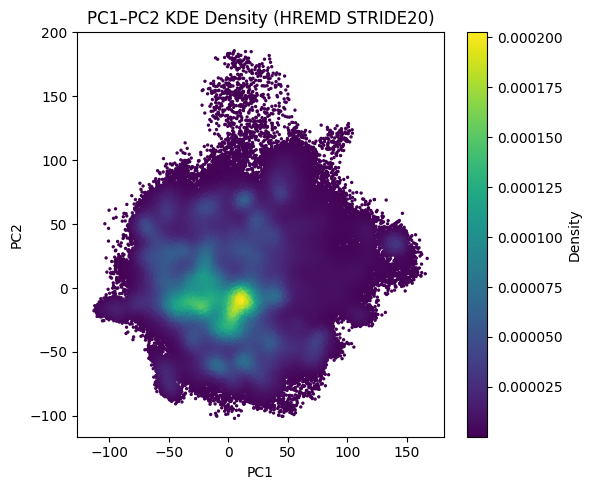

===== JOB COMPLETED =====


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from pathlib import Path
import time

# -------------------------------
# Input
# -------------------------------
pca_file = Path("HREMD_STRIDE20_pca.dat")
assert pca_file.exists(), f"{pca_file} not found"

print(f"[{time.strftime('%H:%M:%S')}] Loading {pca_file}")
data = np.loadtxt(pca_file)

pc1, pc2 = data[:, 1], data[:, 2]
print(f"[{time.strftime('%H:%M:%S')}] Loaded {len(pc1):,} frames")

# -------------------------------
# KDE computation
# -------------------------------
print(f"[{time.strftime('%H:%M:%S')}] Building KDE model")
kde = gaussian_kde(np.vstack([pc1, pc2]))

print(f"[{time.strftime('%H:%M:%S')}] Evaluating KDE")
z = kde(np.vstack([pc1, pc2]))

# -------------------------------
# Save CSV
# -------------------------------
out_csv = pca_file.with_name("PC1_PC2_KDE_density.csv")
np.savetxt(
    out_csv,
    np.column_stack([pc1, pc2, z]),
    delimiter=",",
    header="PC1,PC2,density",
    comments=""
)

print(f"[{time.strftime('%H:%M:%S')}] Saved {out_csv}")

# -------------------------------
# Plot (Jupyter inline)
# -------------------------------
plt.figure(figsize=(6, 5))
sc = plt.scatter(pc1, pc2, c=z, s=2)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PC1–PC2 KDE Density (HREMD STRIDE20)")
plt.colorbar(sc, label="Density")
plt.tight_layout()
plt.show()

print("===== JOB COMPLETED =====")


### 🔗 **Recombine cMD/aMD with Downsampled HREMD (Stride 20)**

The **HREMD PC1–PC2 landscape** is extremely densely sampled, with most frames concentrated in a broad central conformational region and several lower-density extensions (Figure above). When all HREMD frames were combined with the cMD/aMD trajectories, this large sampling excess dominated the joint PCA and effectively masked the previously resolved **cMD/aMD conformational pattern**.

To reduce this **frame-count and sampling imbalance**, the HREMD dataset is therefore **downsampled using stride 20** before concatenation with the complete cMD/aMD trajectory. This retains the overall conformational breadth sampled by HREMD while allowing the cMD/aMD landscape to remain represented in the combined analysis.

In [13]:
%%bash
set -e

PRMTOP="/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/Publish_aMD_cMD_HREMD/aMD_cMD_3PRG_HRMD/cMD_aMD_Ca_5_275.prmtop"

OUT="Ca_aMD_cMD_HREMD_3PRG.nc"

echo "🔗 Concatenating cMD/aMD → HREMD (stride20)"

cpptraj <<EOF
parm ${PRMTOP}

# 1) cMD + aMD first
trajin /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/Publish_aMD_cMD_HREMD/aMD_cMD_3PRG_HRMD/cMD_aMD_Ca_5_275.nc

# 2) HREMD second
trajin HREMD_ALL_Ca_1_275_stride20.nc

trajout ${OUT} netcdf
run
quit
EOF

echo "🎯 Done: wrote ${OUT} in working directory"


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

🔗 Concatenating cMD/aMD → HREMD (stride20)

CPPTRAJ: Trajectory Analysis. V6.29.13 (AmberTools) OpenMP
    ___  ___  ___  ___
     | \/ | \/ | \/ | 
    _|_/\_|_/\_|_/\_|_

| 2 OpenMP threads available.
| Date/time: 01/22/26 01:30:05
| Available memory: 4.202 GB

INPUT: Reading input from 'STDIN'
  [parm /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/Publish_aMD_cMD_HREMD/aMD_cMD_3PRG_HRMD/cMD_aMD_Ca_5_275.prmtop]
	Reading '/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/Publish_aMD_cMD_HREMD/aMD_cMD_3PRG_HRMD/cMD_aMD_Ca_5_275.prmtop' as Amber Topology
	Radius Set: modified Bondi radii (mbondi)
  [trajin /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/Publish_aMD_cMD_HREMD/aMD_cMD_3PRG_HRMD/cMD_aMD_Ca_5_275.nc]
	Reading '/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/Publish_aMD_cMD_HREMD/aMD_cMD_3PRG_HRMD/cMD_aMD_Ca_5_275.nc' as Amber NetCDF
  [trajin HREMD_ALL_Ca_1_275_stride20.nc]
	Reading 'HREMD_ALL_Ca_1_275_stride20.nc' as Amber NetCDF
  [trajout Ca_aMD_cMD_HREMD_3PRG.nc netcdf]

### 📊 **PCA of the Combined cMD/aMD + HREMD Landscape**

Performs **Cα covariance PCA** on the combined **cMD, aMD, and stride-20 HREMD trajectory**. All frames are **autoimaged**, aligned to the **average structure**, and used to construct the covariance matrix before extracting and projecting onto the first **50 principal components**.

This recomputes the PCA basis from the **combined conformational ensemble**, allowing cMD/aMD and downsampled HREMD sampling to be compared within the same PC space.

In [14]:
%%bash
set -e

cpptraj <<EOF
parm /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/Publish_aMD_cMD_HREMD/aMD_cMD_3PRG_HRMD/cMD_aMD_Ca_5_275.prmtop
trajin aMD_cMD_HREMD/Ca_aMD_cMD_HREMD_3PRG.nc

autoimage anchor :1-275@CA
rms first :1-275@CA

average :1-275@CA crdset avgstruct
createcrd trajectory
run

crdaction trajectory rms ref avgstruct :1-275@CA
crdaction trajectory matrix covar name covmatrix :1-275@CA

runanalysis diagmatrix covmatrix out aMD_cMD_HREMD/aMD_cMD_HREMD_3PRG_evecs.dat vecs 50 name Modes
crdaction trajectory projection modes Modes beg 1 end 50 :1-275@CA out aMD_cMD_HREMD/aMD_cMD_HREMD_3PRG_pca.dat

quit
EOF

echo "🎯 PCA completed: aMD + cMD + HREMD (3PRG)"


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us


CPPTRAJ: Trajectory Analysis. V6.29.13 (AmberTools) OpenMP
    ___  ___  ___  ___
     | \/ | \/ | \/ | 
    _|_/\_|_/\_|_/\_|_

| 2 OpenMP threads available.
| Date/time: 01/22/26 01:41:21
| Available memory: 4.060 GB

INPUT: Reading input from 'STDIN'
  [parm /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/Publish_aMD_cMD_HREMD/aMD_cMD_3PRG_HRMD/cMD_aMD_Ca_5_275.prmtop]
	Reading '/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/Publish_aMD_cMD_HREMD/aMD_cMD_3PRG_HRMD/cMD_aMD_Ca_5_275.prmtop' as Amber Topology
	Radius Set: modified Bondi radii (mbondi)
  [trajin aMD_cMD_HREMD/Ca_aMD_cMD_HREMD_3PRG.nc]
	Reading 'aMD_cMD_HREMD/Ca_aMD_cMD_HREMD_3PRG.nc' as Amber NetCDF
  [autoimage anchor :1-275@CA]
    AUTOIMAGE: To box center based on center of mass, anchor mask is [:1-275@CA]
	Auto-imaging using molecule distances.
  [rms first :1-275@CA]
    RMSD: (:1-275@CA), reference is first frame (:1-275@CA).
	Best-fit RMSD will be calculated, coords will be rotated and translated.
  [average :1

### 🧭 **Map Individual HREMD Replicas onto the Combined PCA Landscape**

Projects each of the **64 HREMD λ trajectories** onto the common **cMD/aMD + HREMD PCA landscape**. The complete **cMD/aMD ensemble** is shown in grey as a reference background, while each HREMD replica is displayed separately in an **8 × 8 grid**.

Within each λ panel, frames are colored according to their **temporal progression from start → end**, allowing the trajectory of each replica through PC space to be visualized independently. A **white star** marks the starting frame of each replica.

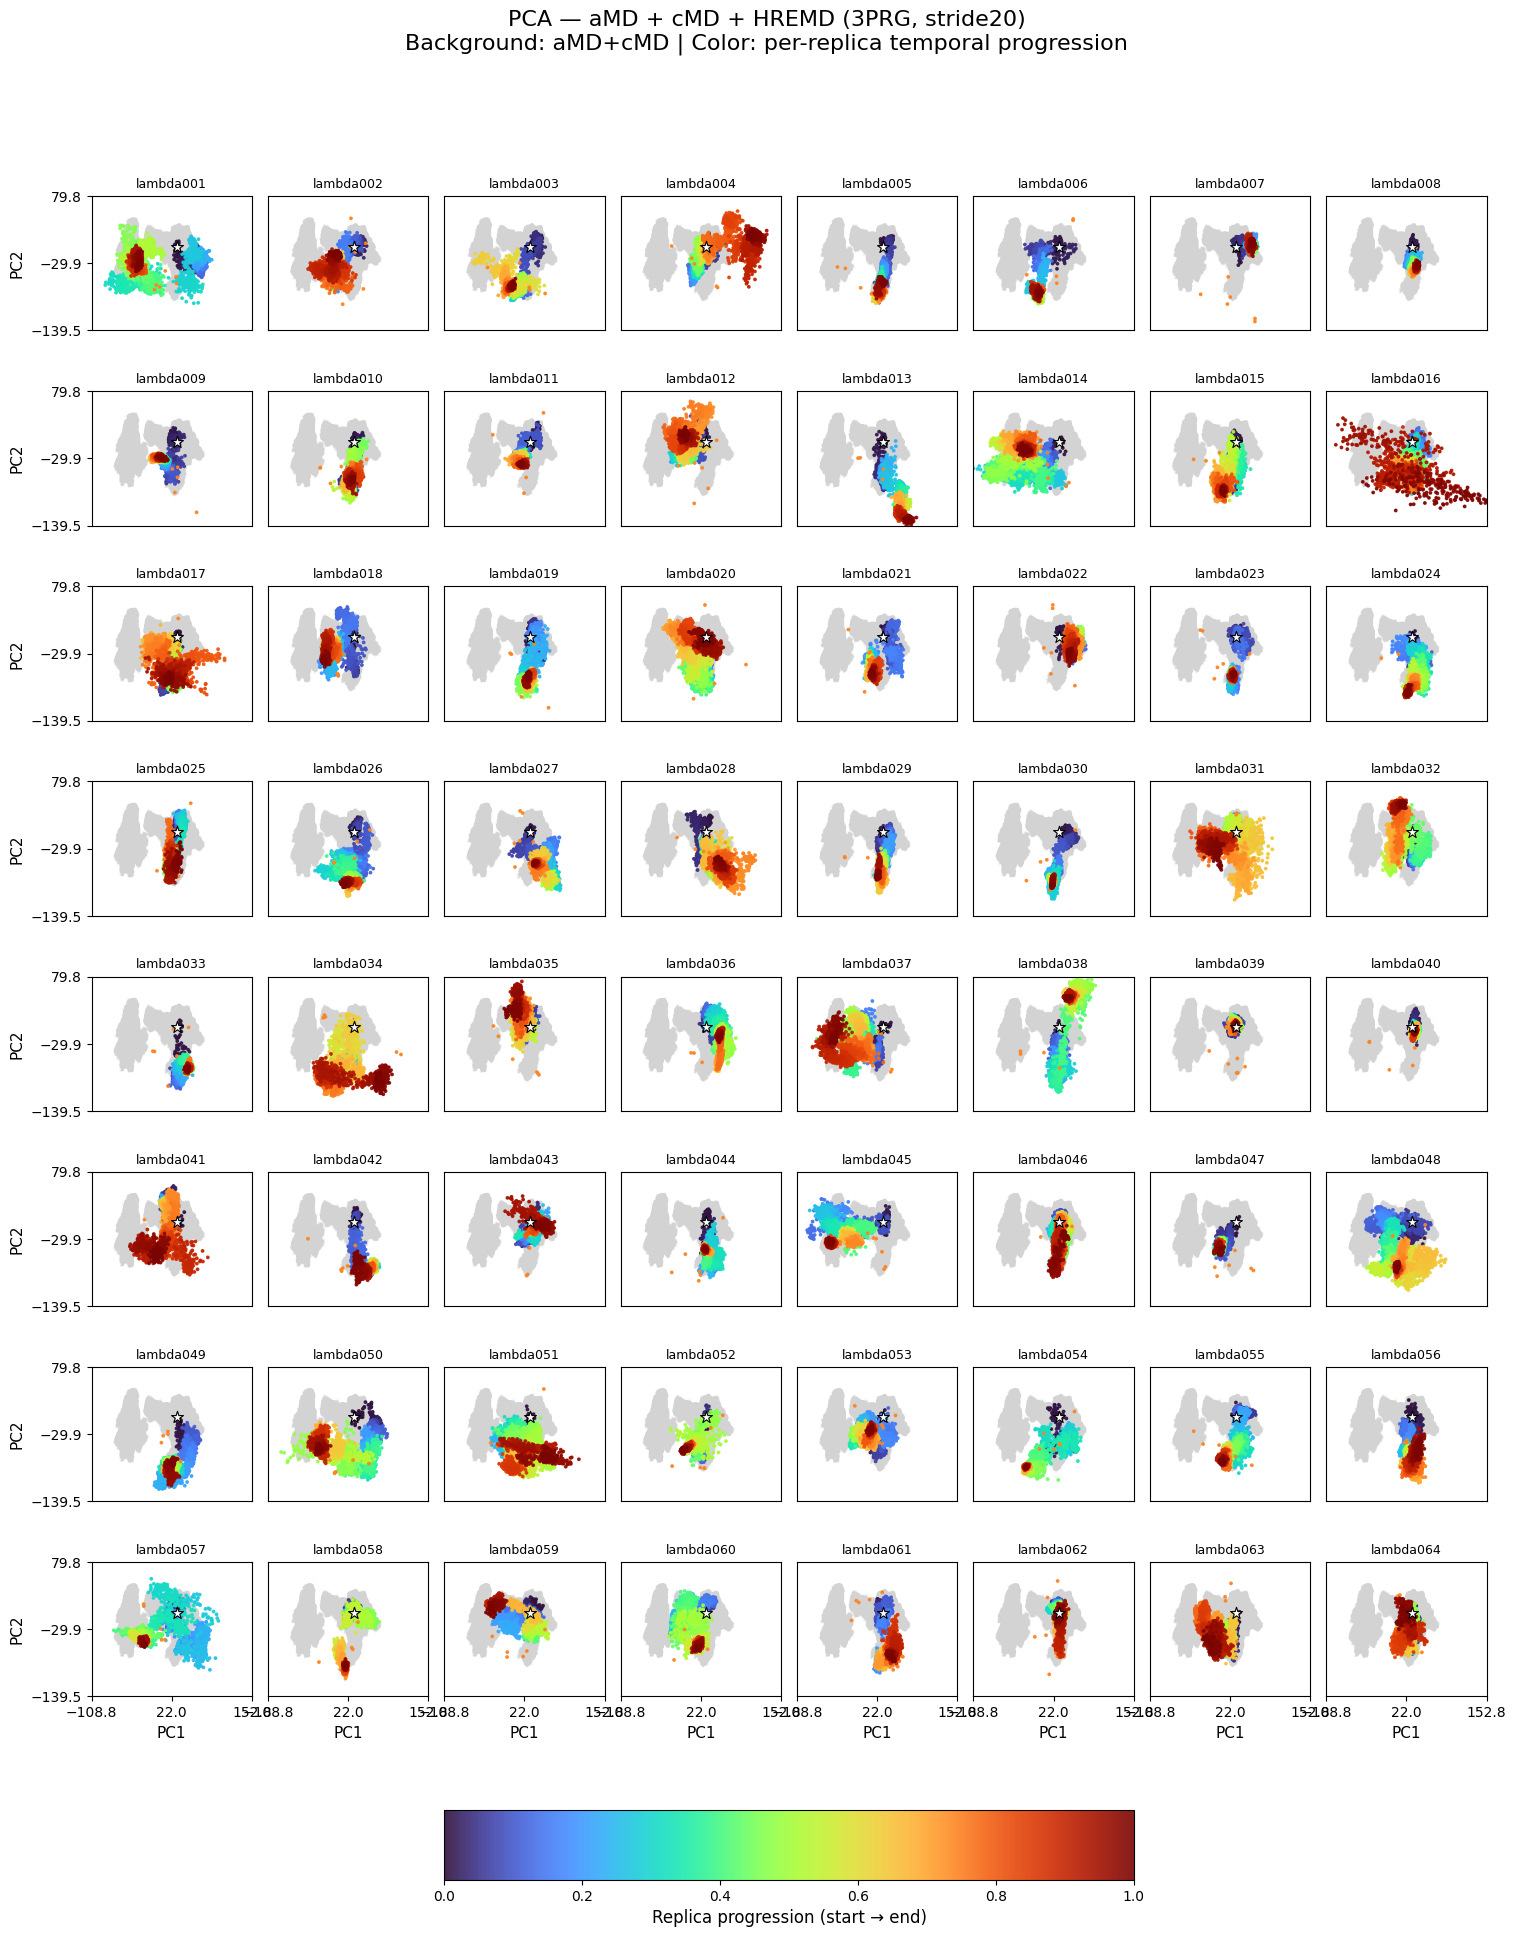

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# -------------------------------------------------
# Input PCA file
# -------------------------------------------------
PCA_FILE = Path("aMD_cMD_HREMD/aMD_cMD_HREMD_3PRG_pca.dat")
assert PCA_FILE.exists(), f"{PCA_FILE} not found"

data = np.loadtxt(PCA_FILE)
pc1 = data[:, 1]
pc2 = -1.0 * data[:, 2]   # FLIP PC2

# -------------------------------------------------
# Frame bookkeeping
# -------------------------------------------------
AMD_CMD_FRAMES = 5_400_000
HREMD_FRAMES   = 377_152

TOTAL_CHUNKS = 64
CHUNK_SIZE   = HREMD_FRAMES // TOTAL_CHUNKS

# -------------------------------------------------
# Global axis limits (square)
# -------------------------------------------------
xmin, xmax = pc1.min(), pc1.max()
ymin, ymax = pc2.min(), pc2.max()

xmid = 0.5 * (xmin + xmax)
ymid = 0.5 * (ymin + ymax)

xlim = (xmin, xmax)
ylim = (ymin, ymax)

# -------------------------------------------------
# Figure layout
# -------------------------------------------------
fig = plt.figure(figsize=(18, 22))
gs = fig.add_gridspec(
    10, 8,
    height_ratios=[1]*8 + [0.15, 0.45],
    hspace=0.30,
    wspace=0.10
)

axes = np.array([[fig.add_subplot(gs[i, j]) for j in range(8)] for i in range(8)])

# -------------------------------------------------
# Background: aMD + cMD
# -------------------------------------------------
for ax in axes.ravel():
    ax.scatter(
        pc1[:AMD_CMD_FRAMES],
        pc2[:AMD_CMD_FRAMES],
        color="lightgrey",
        s=1,
        alpha=0.15,
        rasterized=True
    )
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])

# -------------------------------------------------
# HREMD: per-replica start → end coloring
# -------------------------------------------------
sc = None
for c in range(TOTAL_CHUNKS):
    ax = axes[c // 8, c % 8]

    start = AMD_CMD_FRAMES + c * CHUNK_SIZE
    end   = start + CHUNK_SIZE

    local_t = np.linspace(0, 1, end - start)

    sc = ax.scatter(
        pc1[start:end],
        pc2[start:end],
        c=local_t,
        cmap="turbo",
        s=3,
        alpha=0.9
    )

    ax.scatter(
        pc1[start], pc2[start],
        marker="*", s=80,
        facecolor="white",
        edgecolor="black",
        linewidth=0.8,
        zorder=10
    )

    ax.set_title(f"lambda{c+1:03d}", fontsize=9)

# -------------------------------------------------
# Axis ticks ONLY on outer border (3 ticks)
# -------------------------------------------------
for ax in axes[-1, :]:
    ax.set_xticks([xmin, xmid, xmax])
    ax.set_xlabel("PC1", fontsize=11)

for ax in axes[:, 0]:
    ax.set_yticks([ymin, ymid, ymax])
    ax.set_ylabel("PC2", fontsize=11)

# -------------------------------------------------
# Short, centered colorbar (own row)
# -------------------------------------------------
cax = fig.add_subplot(gs[9, 2:6])
cbar = fig.colorbar(sc, cax=cax, orientation="horizontal")
cbar.set_label("Replica progression (start → end)", fontsize=12)

# -------------------------------------------------
# Title
# -------------------------------------------------
plt.suptitle(
    "PCA — aMD + cMD + HREMD (3PRG, stride20)\n"
    "Background: aMD+cMD | Color: per-replica temporal progression",
    fontsize=16, y=0.96
)

plt.show()
